# Gold Volatility Prediction with an ANN
**Problem:** predict how volatile gold will be over the next 5 trading days (the standard deviation of its daily % changes). This is a risk-forecasting problem.
**Why volatility:** gold's direction is close to random, but its volatility is persistent (calm days follow calm days, turbulent days follow turbulent days), so it can be learned.
**Data:** gold, silver, dollar index, oil, 10-year yield, VIX (Yahoo Finance) + real yield and inflation expectations (FRED).
**Pipeline:** data → EDA → features → ANN (L2 + Dropout + Early Stopping) → manual tuning → evaluation → save/load → inference.
**Compared against:** a baseline ("volatility over the next 5 days = volatility over the last 10 days") and the training-set average.

## 0. Setup

In [ ]:
import time
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import tensorflow as tf
from tensorflow import keras
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

tf.keras.utils.set_random_seed(42)

## 1. Data
Market prices from Yahoo Finance, and two macro series from FRED (real yield and inflation expectations). FRED values are shifted by one day because they are published a day late.

In [ ]:
START = "2005-01-01"
TICKERS = {"gold": "GC=F", "silver": "SI=F", "dxy": "DX-Y.NYB", "oil": "CL=F",
           "yield10": "^TNX", "vix": "^VIX"}
FRED = {"real_yield": "DFII10", "inflation_exp": "T10YIE"}
headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                         "(KHTML, like Gecko) Chrome/120.0 Safari/537.36"}

def get_yahoo(ticker):
    url = f"https://query1.finance.yahoo.com/v8/finance/chart/{ticker}"
    params = {"period1": int(pd.Timestamp(START).timestamp()),
              "period2": int(time.time()), "interval": "1d"}
    r = requests.get(url, params=params, headers=headers, timeout=30)
    r.raise_for_status()
    res = r.json()["chart"]["result"][0]
    dates = pd.to_datetime(res["timestamp"], unit="s").normalize()
    prices = pd.Series(res["indicators"]["quote"][0]["close"], index=dates)
    return prices[~prices.index.duplicated(keep="last")].loc[START:]

def get_fred(series_id):
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
    s = pd.read_csv(url, index_col=0, parse_dates=True).iloc[:, 0]
    return pd.to_numeric(s, errors="coerce").loc[START:].shift(1)

frames = {}
for name, ticker in TICKERS.items():
    try:
        frames[name] = get_yahoo(ticker)
        print(name, "OK", len(frames[name]), "rows")
    except Exception as e:
        print(name, "FAILED", e)
for name, series_id in FRED.items():
    try:
        frames[name] = get_fred(series_id)
        print(name, "OK", len(frames[name]), "rows")
    except Exception as e:
        print(name, "FAILED", e)

assert "gold" in frames, "Gold download failed - see messages above"
data = pd.DataFrame(frames).dropna(subset=["gold"]).ffill().dropna()
LEVEL_COLS = [c for c in FRED if c in data.columns]
HELPERS = [c for c in data.columns if c != "gold"]
PRICE_COLS = [c for c in data.columns if c not in LEVEL_COLS]
print(data.shape, "from", data.index[0].date(), "to", data.index[-1].date())
data.tail()

gold OK 5533 rows
silver OK 5533 rows
dxy OK 6674 rows
oil OK 5533 rows
yield10 OK 5507 rows
vix OK 5710 rows
real_yield OK 5709 rows
inflation_exp OK 5710 rows
(5502, 8) from 2005-01-04 to 2026-11-20


,gold,silver,dxy,oil,yield10,vix,real_yield,inflation_exp
2026-11-16,3853.000000,46.785000,103.550003,85.720001,5.121,22.910000,2.91,2.24
2026-11-17,3864.199951,47.287998,103.489998,86.010002,5.103,25.459999,2.92,2.20
2026-11-18,3741.899902,44.999001,103.860001,83.260002,5.066,24.559999,2.89,2.21
2026-11-19,3685.500000,44.318001,103.900002,83.209999,5.052,28.440001,2.88,2.19
2026-11-20,3515.399902,41.035000,103.809998,83.980003,4.912,35.889999,2.88,2.16


## 2. EDA

In [ ]:
print(data.shape)
print(data.isna().sum())
data.describe()

(5502, 8)
gold             0
silver           0
dxy              0
oil              0
yield10          0
vix              0
real_yield       0
inflation_exp    0
dtype: int64


,gold,silver,dxy,oil,yield10,vix,real_yield,inflation_exp
count,5502.000000,5502.000000,5502.000000,5502.000000,5502.000000,5502.000000,5502.000000,5502.000000
mean,1566.045492,22.601256,90.664024,72.106569,3.029925,19.122206,0.935234,2.101474
std,886.625659,13.031003,9.640119,20.950452,1.158921,8.506437,1.020740,0.396206
min,412.600006,6.427000,71.330002,-37.630001,0.499000,9.140000,-1.190000,0.040000
25%,1123.624969,15.326250,81.522497,56.820000,2.071250,13.552500,0.240000,1.870000
50%,1322.199951,18.482500,92.230003,70.535000,2.900500,16.799999,0.820000,2.220000
75%,1798.725037,26.211000,98.307499,87.907503,4.115000,21.969999,1.830000,2.360000
max,5318.399902,115.080002,114.110001,145.289993,5.311000,82.690002,3.150000,3.020000


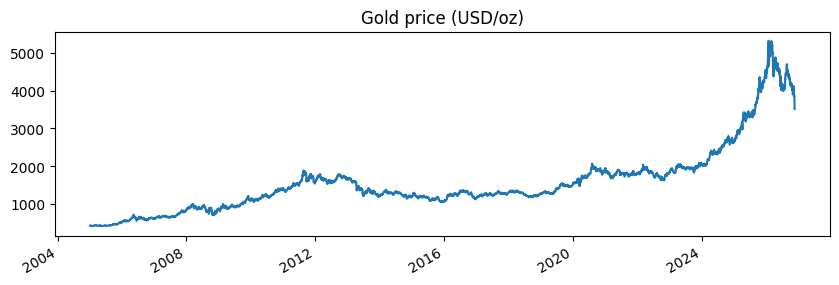

In [ ]:
data["gold"].plot(figsize=(10, 3), title="Gold price (USD/oz)")
plt.show()

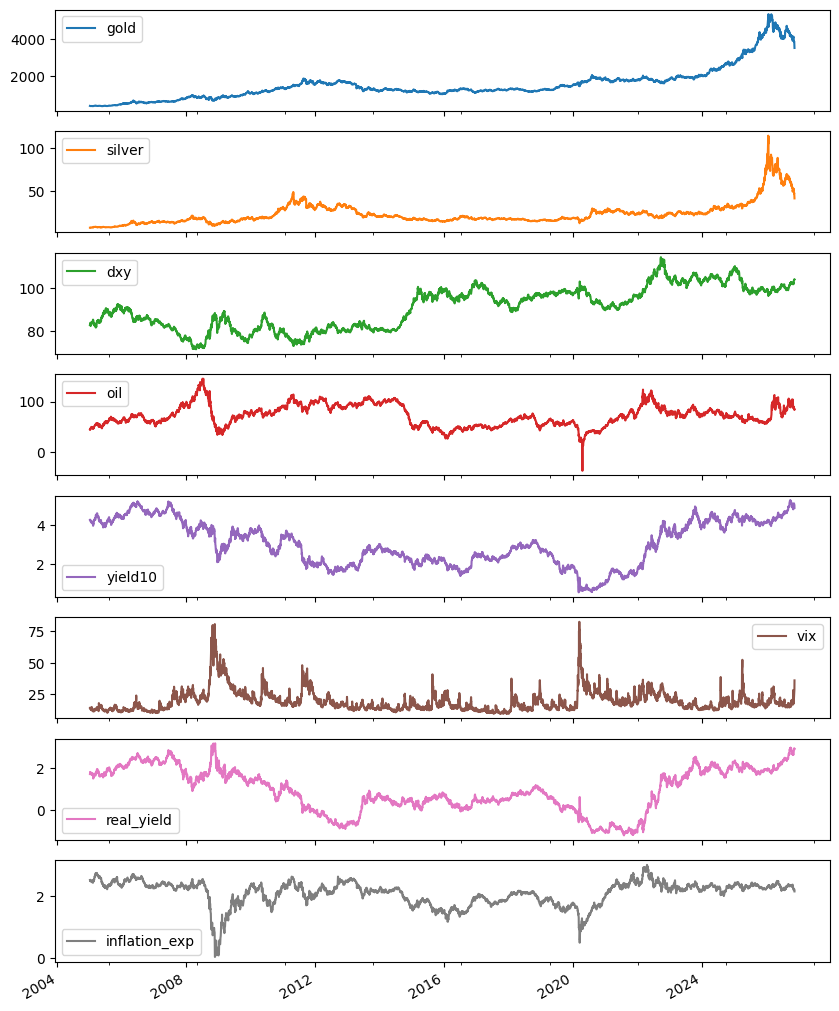

In [ ]:
data.plot(subplots=True, figsize=(10, 14))
plt.show()

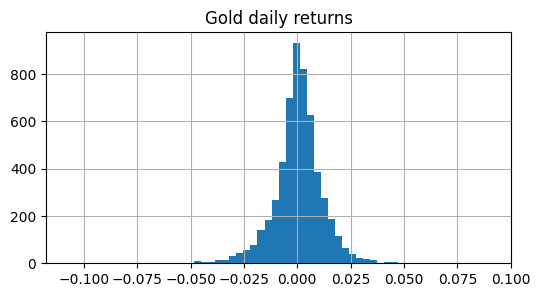

In [ ]:
returns = data[PRICE_COLS].pct_change().dropna()
returns["gold"].hist(bins=60, figsize=(6, 3))
plt.title("Gold daily returns")
plt.show()

In [ ]:
print(returns.corr().round(2))

         gold  silver   dxy   oil  yield10   vix
gold     1.00    0.79 -0.38  0.08    -0.15 -0.02
silver   0.79    1.00 -0.36  0.10    -0.04 -0.13
dxy     -0.38   -0.36  1.00 -0.09     0.11  0.09
oil      0.08    0.10 -0.09  1.00     0.14 -0.11
yield10 -0.15   -0.04  0.11  0.14     1.00 -0.23
vix     -0.02   -0.13  0.09 -0.11    -0.23  1.00


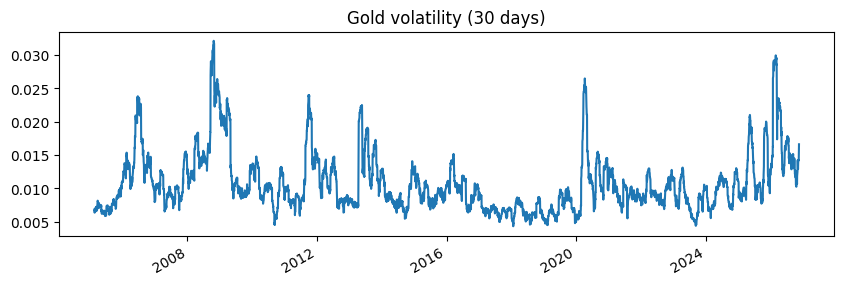

In [ ]:
returns["gold"].rolling(30).std().plot(figsize=(10, 3), title="Gold volatility (30 days)")
plt.show()

**What the EDA shows:** gold has a long upward trend, so we predict its *change* rather than the raw price. Daily returns are centered near zero and bell-shaped, so short-term moves are close to random. We use a 5-day horizon to reduce the daily noise.

## 3. Features and target
**Target:** volatility of gold over the next 5 trading days (std of daily % changes, in %).
**Inputs:** gold's last 5 daily changes and their sizes (absolute values), 10-day and 20-day volatility, the VIX level, today's change of the other markets, and the level and change of the real yield and inflation expectations.

In [ ]:
HORIZON = 5

def make_features(data):
    r = data.pct_change() * 100
    X = pd.DataFrame(index=data.index)
    for i in range(5):
        X[f"gold_lag{i}"] = r["gold"].shift(i)
        X[f"abs_lag{i}"] = r["gold"].shift(i).abs()
    X["gold_vol10"] = r["gold"].rolling(10).std()
    X["gold_vol20"] = r["gold"].rolling(20).std()
    if "vix" in data.columns:
        X["vix_level"] = data["vix"]
    for c in HELPERS:
        if c in LEVEL_COLS:
            X[f"{c}_level"] = data[c]
            X[f"{c}_diff"] = data[c].diff()
        else:
            X[f"{c}_change"] = r[c]
    return X

X = make_features(data)
daily = data["gold"].pct_change() * 100
y = daily.rolling(HORIZON).std().shift(-HORIZON).rename("target")
df = pd.concat([X, y], axis=1).dropna()
cols = list(X.columns)
print(df.shape)
print(df.corr()["target"].drop("target").sort_values().round(3))

(5477, 23)
inflation_exp_level   -0.120
inflation_exp_diff    -0.065
silver_change         -0.029
oil_change            -0.027
yield10_change        -0.011
gold_lag0             -0.010
gold_lag2              0.002
real_yield_diff        0.004
gold_lag1              0.005
gold_lag4              0.005
gold_lag3              0.008
dxy_change             0.011
vix_change             0.028
real_yield_level       0.167
abs_lag4               0.244
abs_lag2               0.251
abs_lag0               0.251
abs_lag3               0.253
abs_lag1               0.262
vix_level              0.394
gold_vol10             0.475
gold_vol20             0.506
Name: target, dtype: float64


## 4. Train / validation / test split
Split by time, with no shuffling. Because each target looks 5 days ahead, we leave a 5-day gap between the sets so no information leaks across them. The scaler learns from the training set only.

In [ ]:
n = len(df)
i, j = int(n * 0.70), int(n * 0.85)
train = df.iloc[:i]
val = df.iloc[i + HORIZON: j]
test = df.iloc[j + HORIZON:]

scaler = StandardScaler().fit(train[cols])
X_train, X_val, X_test = [scaler.transform(d[cols]) for d in (train, val, test)]
y_train, y_val, y_test = train["target"].values, val["target"].values, test["target"].values
print(len(train), len(val), len(test), "| test starts:", test.index[0].date())

3833 817 817 | test starts: 2023-08-18


## 5. Model and manual tuning
ANN with **L2**, **Dropout** and **Early Stopping**. We train one model for each setting in the list below and keep the one with the lowest validation loss. **Group work: each member edits the `settings` list (or the model) with a different idea.**

In [ ]:
def build_model(units=64, dropout=0.2, l2=1e-4, lr=1e-3):
    model = keras.Sequential([
        keras.layers.Input(shape=(len(cols),)),
        keras.layers.Dense(units, activation="relu", kernel_regularizer=keras.regularizers.l2(l2)),
        keras.layers.Dropout(dropout),
        keras.layers.Dense(units // 2, activation="relu", kernel_regularizer=keras.regularizers.l2(l2)),
        keras.layers.Dropout(dropout),
        keras.layers.Dense(1),
    ])
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="mse")
    return model

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                           restore_best_weights=True)

settings = [
    {"units": 32,  "dropout": 0.1, "l2": 1e-4, "lr": 1e-3},
    {"units": 64,  "dropout": 0.2, "l2": 1e-4, "lr": 1e-3},
    {"units": 128, "dropout": 0.3, "l2": 1e-3, "lr": 1e-3},
    {"units": 64,  "dropout": 0.2, "l2": 1e-4, "lr": 3e-4},
]

best_loss, best_settings = 1e9, None
for s in settings:
    m = build_model(**s)
    h = m.fit(X_train, y_train, validation_data=(X_val, y_val),
              epochs=100, batch_size=32, callbacks=[early_stop], verbose=0)
    loss = min(h.history["val_loss"])
    print(s, "-> val_loss:", round(loss, 4))
    if loss < best_loss:
        best_loss, best_settings = loss, s

print("Best settings:", best_settings)

{'units': 32, 'dropout': 0.1, 'l2': 0.0001, 'lr': 0.001} -> val_loss: 0.2346
{'units': 64, 'dropout': 0.2, 'l2': 0.0001, 'lr': 0.001} -> val_loss: 0.2242
{'units': 128, 'dropout': 0.3, 'l2': 0.001, 'lr': 0.001} -> val_loss: 0.2847
{'units': 64, 'dropout': 0.2, 'l2': 0.0001, 'lr': 0.0003} -> val_loss: 0.2386
Best settings: {'units': 64, 'dropout': 0.2, 'l2': 0.0001, 'lr': 0.001}


## 6. Train the final model

In [ ]:
model = build_model(**best_settings)
history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                    epochs=200, batch_size=32, callbacks=[early_stop], verbose=0)
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,757 (42.02 KB)

 Trainable params: 3,585 (14.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 7,172 (28.02 KB)

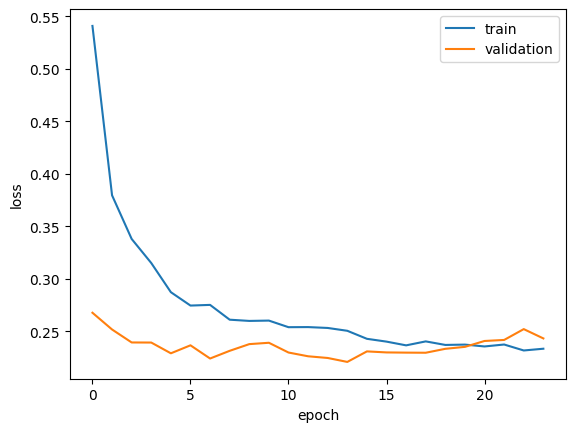

In [ ]:
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

## 7. Evaluation on the test set
We compare the ANN with two simple baselines: (1) next volatility = current 10-day volatility, (2) always predict the training average.

In [ ]:
pred = model.predict(X_test, verbose=0).ravel()
baseline = test["gold_vol10"].values
average = np.full(len(y_test), y_train.mean())

def scores(actual, predicted):
    return {"MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
            "R2": r2_score(actual, predicted)}

results = pd.DataFrame({"ANN": scores(y_test, pred),
                        "Baseline (last 10-day vol)": scores(y_test, baseline),
                        "Training average": scores(y_test, average)}).T
results.loc["Baseline (last 20-day vol)"] = scores(y_test, test["gold_vol20"].values)
print(results.round(3))

                              MAE   RMSE     R2
ANN                         0.408  0.623  0.223
Baseline (last 10-day vol)  0.461  0.708 -0.002
Training average            0.483  0.726 -0.054
Baseline (last 20-day vol)  0.447  0.684  0.065


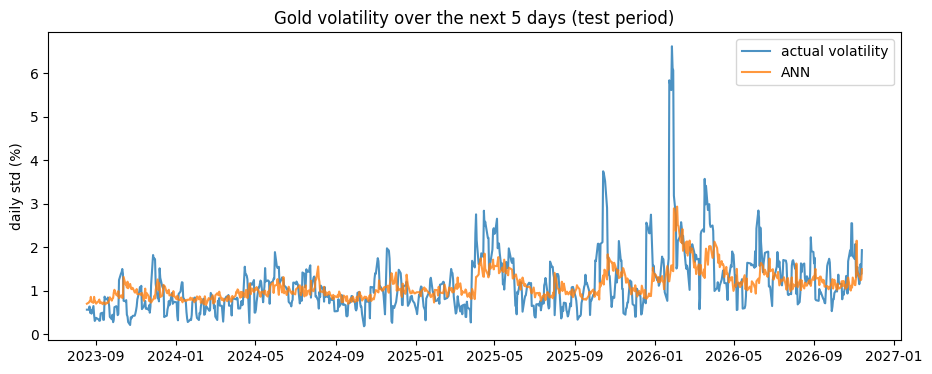

In [ ]:
plt.figure(figsize=(11, 4))
plt.plot(test.index, y_test, label="actual volatility", alpha=0.8)
plt.plot(test.index, pred, label="ANN", alpha=0.8)
plt.title("Gold volatility over the next 5 days (test period)")
plt.ylabel("daily std (%)")
plt.legend()
plt.show()

**Reading the results:** R² above 0 means the model explains part of the changes in volatility (0 = no better than the average). The key comparison is the ANN against the "last 10-day volatility" baseline: if the ANN is better, the extra features (VIX, macro data) add information.

## 9. Save and load

In [ ]:
model.save("gold_ann.keras")
joblib.dump({"scaler": scaler, "cols": cols}, "preprocess.joblib")

loaded = keras.models.load_model("gold_ann.keras")
same = np.allclose(loaded.predict(X_test, verbose=0), model.predict(X_test, verbose=0))
print("Loaded model gives the same predictions:", same)

Loaded model gives the same predictions: True


## 10. Inference
Give it the recent prices table, get the predicted gold volatility for the next 5 days.

In [ ]:
def predict_volatility(data):
    saved = joblib.load("preprocess.joblib")
    model = keras.models.load_model("gold_ann.keras")
    X = make_features(data)
    x = saved["scaler"].transform(X[saved["cols"]].iloc[[-1]])
    vol = float(model.predict(x, verbose=0)[0, 0])
    return {"as_of": str(data.index[-1].date()),
            "volatility_last_10_days_%": round(float(X["gold_vol10"].iloc[-1]), 3),
            "predicted_volatility_next_5_days_%": round(vol, 3)}

predict_volatility(data)

{'as_of': '2026-11-20',
 'volatility_last_10_days_%': 1.742,
 'predicted_volatility_next_5_days_%': 1.615}

## 11. Limitations
- We predict how large the moves will be, not their direction: gold's direction was close to unpredictable in our earlier experiments (direction models did not beat the majority-class baseline).
- Volatility is persistent, so the "last 10-day volatility" baseline is strong and hard to beat by much.
- Sudden news (wars, central bank decisions) can create volatility that no price-based feature anticipates.
- This is a course project, not financial advice.